### Import libraries

In [1]:
from pathlib import Path
from PIL import Image
import pandas as pd
import hashlib
import matplotlib.pyplot as plt

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() in {"notebook", "notebooks"}:
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

CSV_PATH = ROOT / "data" / "processed" / "rice_leaf_images.csv"
PROCESSED_DIR = ROOT / "data" / "processed"

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Dataset CSV not found: {CSV_PATH}\n"
        "Make sure you have cloned the repository and created the dataset CSV."
    )

df = pd.read_csv(CSV_PATH)

print("Project root:", ROOT)
print("Images to validate:", len(df))

Project root: d:\My_Project\Analyse\AI-Paddy-Farming-Intelligence
Images to validate: 6712


### Check image quality and duplicates

In [2]:
valid_records = []
invalid_images = []

for row in df.itertuples(index=False):

    image_path = ROOT / row.image_path

    try:
        with Image.open(image_path) as image:
            image.verify()

        image_hash = hashlib.sha256(
            image_path.read_bytes()
        ).hexdigest()

        valid_records.append({
            "image_path": row.image_path,
            "label": row.label,
            "image_hash": image_hash
        })

    except Exception as error:
        invalid_images.append({
            "image_path": row.image_path,
            "error": str(error)
        })

valid_df = pd.DataFrame(valid_records)

print("Valid images:", len(valid_df))
print("Invalid images:", len(invalid_images))


Valid images: 6712
Invalid images: 0


###  Save validation results

In [5]:
valid_df.to_csv(
    PROCESSED_DIR / "valid_rice_leaf_images.csv",
    index=False,
    encoding="utf-8-sig"
)

invalid_df = pd.DataFrame(invalid_images)

print("Validation reports saved successfully.")

Validation reports saved successfully.


### Remove duplicate images

In [6]:
conflicting_hashes = (
    valid_df.groupby("image_hash")["label"]
    .nunique()
)

conflicting_hashes = conflicting_hashes[
    conflicting_hashes > 1
].index

conflicting_df = valid_df[
    valid_df["image_hash"].isin(conflicting_hashes)
]

valid_df = valid_df[
    ~valid_df["image_hash"].isin(conflicting_hashes)
].copy()

before_deduplication = len(valid_df)

clean_df = valid_df.drop_duplicates(
    subset="image_hash",
    keep="first"
).copy()

duplicates_removed = before_deduplication - len(clean_df)

clean_df = clean_df.drop(columns=["image_hash"])

CLEAN_PATH = PROCESSED_DIR / "rice_leaf_images_clean.csv"

clean_df.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")

print("Exact duplicate images removed:", duplicates_removed)
print("Conflicting-label images removed:", len(conflicting_df))
print("Final clean image count:", len(clean_df))
print("Saved:", CLEAN_PATH)

Exact duplicate images removed: 1
Conflicting-label images removed: 0
Final clean image count: 6711
Saved: d:\My_Project\Analyse\AI-Paddy-Farming-Intelligence\data\processed\rice_leaf_images_clean.csv


### Category distribution

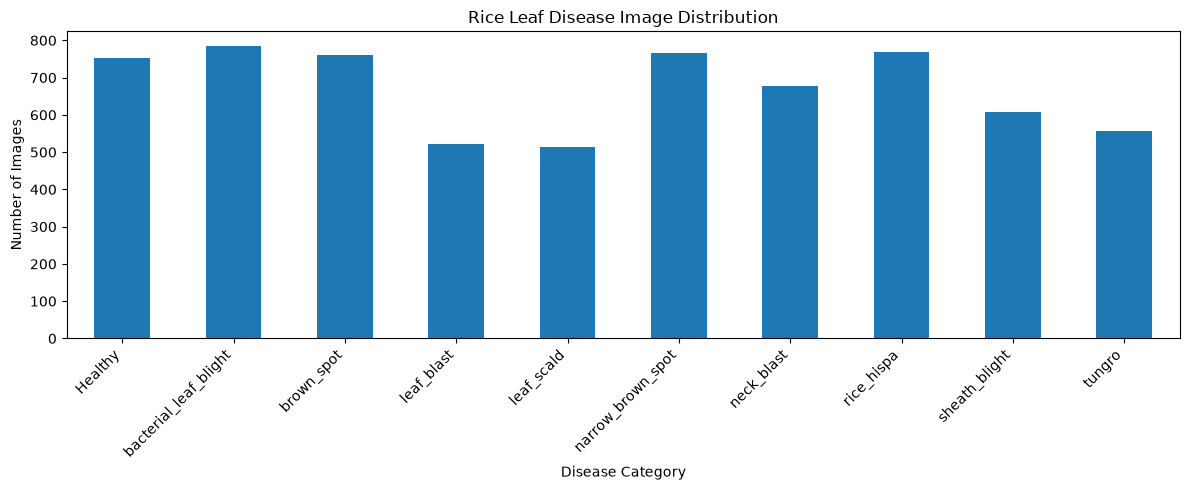

,image_count
label,
Healthy,753
bacterial_leaf_blight,785
brown_spot,760
leaf_blast,521
leaf_scald,514
narrow_brown_spot,767
neck_blast,677
rice_hispa,770
sheath_blight,608


In [7]:
class_counts = clean_df["label"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
class_counts.plot(kind="bar")

plt.title("Rice Leaf Disease Image Distribution")
plt.xlabel("Disease Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(class_counts.to_frame("image_count"))

### Check image dimensions

In [8]:
image_info = []

for row in clean_df.itertuples(index=False):

    image_path = ROOT / row.image_path

    with Image.open(image_path) as image:
        width, height = image.size

    image_info.append({
        "label": row.label,
        "width": width,
        "height": height
    })

image_info_df = pd.DataFrame(image_info)

display(image_info_df.groupby("label")[["width", "height"]].describe())

width                                            \
                       count         mean         std     min      25%   
label                                                                    
Healthy                753.0  1898.094290  762.921548   427.0  1600.00   
bacterial_leaf_blight  785.0  1481.030573  371.330126   183.0  1600.00   
brown_spot             760.0  1600.000000    0.000000  1600.0  1600.00   
leaf_blast             521.0  1600.000000    0.000000  1600.0  1600.00   
leaf_scald             514.0  1600.000000    0.000000  1600.0  1600.00   
narrow_brown_spot      767.0  1600.000000    0.000000  1600.0  1600.00   
neck_blast             677.0  3120.000000    0.000000  3120.0  3120.00   
rice_hispa             770.0  1624.964935  351.562772   431.0  1600.00   
sheath_blight          608.0  1597.416118  332.346725   390.0  1600.00   
tungro                 556.0   501.906475  414.385917   211.0   287.75   

                                              height                           \
                          50%     75%     max  count         mean         std   
label                                                                           
Healthy                1600.0  1600.0  4000.0  753.0  1767.543161  710.343844   
bacterial_leaf_blight  1600.0  1600.0  1600.0  785.0  1481.505732  371.942550   
brown_spot             1600.0  1600.0  1600.0  760.0  1541.578947  141.356618   
leaf_blast             1600.0  1600.0  1600.0  521.0  1439.539347  196.241068   
leaf_scald             1600.0  1600.0  1600.0  514.0  1515.953307  163.115279   
narrow_brown_spot      1600.0  1600.0  1600.0  767.0  1464.203390  189.351236   
neck_blast             3120.0  3120.0  3120.0  677.0  3120.000000    0.000000   
rice_hispa             1600.0  1600.0  4000.0  770.0  1235.446753  247.873464   
sheath_blight          1600.0  1600.0  4000.0  608.0  1239.932566  363.770422   
tungro                  340.0   497.0  1970.0  556.0   541.255396  524.075845   

                                                                
                          min     25%     50%      75%     max  
label                                                           
Healthy                 441.0  1200.0  1600.0  1600.00  3840.0  
bacterial_leaf_blight   178.0  1600.0  1600.0  1600.00  1600.0  
brown_spot             1200.0  1600.0  1600.0  1600.00  1600.0  
leaf_blast             1200.0  1200.0  1600.0  1600.00  1600.0  
leaf_scald             1200.0  1600.0  1600.0  1600.00  1600.0  
narrow_brown_spot      1200.0  1200.0  1600.0  1600.00  1600.0  
neck_blast             3120.0  3120.0  3120.0  3120.00  3120.0  
rice_hispa             1086.0  1200.0  1200.0  1200.00  3000.0  
sheath_blight           469.0  1200.0  1200.0  1200.00  3264.0  
tungro                  209.0   283.0   344.5   496.25  1920.0